# Recruitment Data Detective | Evaluation Report
### ZEIL Hackathon 2026 · Prompt experiment

**Question:** Does a structured investigation protocol improve agent reliability without increasing unsupported claims?

> This notebook reads actual `eval_results/paired_raw.json` or `eval_results/before_after.json`. No missing scores are filled in or invented. The synthetic `high_conversion` example is available as a one-case illustration only.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'eval_results').exists() and (ROOT.parent / 'eval_results').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'eval_results'
PATHS = [DATA / 'before_after.json', DATA / 'paired_raw.json']
source = next((p for p in PATHS if p.exists()), None)
if source:
    raw = json.loads(source.read_text(encoding='utf-8'))
    records = raw['results'] if isinstance(raw, dict) and 'results' in raw else raw
    print('Loaded:', source, '| Records:', len(records))
else:
    records = [
        {'case':'high_conversion','version':'baseline','status':'PASS','tool_used':True,'detector_used':True,'actual_flag':False,'expected_flag':False,'report_generated':True,'error':None},
        {'case':'high_conversion','version':'improved','status':'PASS','tool_used':True,'detector_used':True,'actual_flag':False,'expected_flag':False,'report_generated':True,'error':None},
    ]
    print('ILLUSTRATION ONLY: using the one user-provided matched case; full experiment file not found.')
df = pd.DataFrame(records)
for col in ['tool_used','detector_used','report_generated']:
    if col not in df: df[col] = False
if 'status' not in df:
    df['status'] = df.get('passed', pd.Series(False, index=df.index)).map({True:'PASS',False:'FAIL'})
df['status'] = df['status'].fillna('FAIL')
display(df[['case','version','status']].reset_index(drop=True).style.hide(axis='index'))

Loaded: /Users/vicmon/ZEIL/eval_results/before_after.json | Records: 14


case,version,status
normal,baseline,PASS
normal,improved,PASS
screening_drop,baseline,PASS
screening_drop,improved,PASS
high_conversion,baseline,PASS
high_conversion,improved,PASS
zero_interviews,baseline,PASS
zero_interviews,improved,PASS
low_offers,baseline,PASS
low_offers,improved,PASS


## 01 / Scoreboard
**End-to-end pass rate** uses all attempted calls, including infrastructure errors. **Pass rate on completed calls** excludes `API_ERROR` and is therefore conditional. Neither metric alone evaluates factual accuracy in the generated prose.

Prompt,Attempts,Pass,Fail,API errors,End-to-end %,Completed-pass %,Detector invoked %
Baseline,7,7,0,0,100.0,100.0,100.0
Improved,7,7,0,0,100.0,100.0,100.0


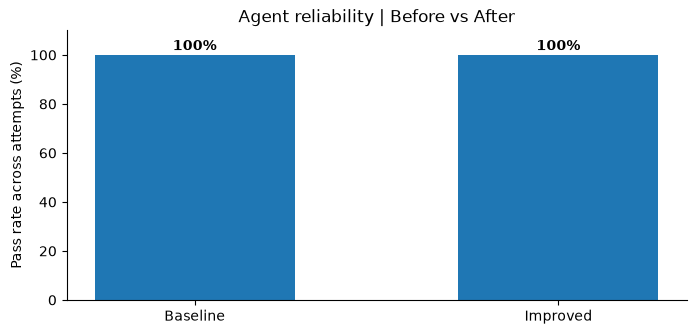

In [2]:
scores=[]
for version in ['baseline','improved']:
    x=df[df.version==version]
    if x.empty: continue
    n=len(x); passed=int((x.status=='PASS').sum()); errors=int((x.status=='API_ERROR').sum()); completed=n-errors
    scores.append({'Prompt':version.title(),'Attempts':n,'Pass':passed,'Fail':int((x.status=='FAIL').sum()),'API errors':errors,
                   'End-to-end %':round(100*passed/n,1),'Completed-pass %':round(100*passed/completed,1) if completed else float('nan'),
                   'Detector invoked %':round(100*x.detector_used.fillna(False).astype(bool).mean(),1)})
summary=pd.DataFrame(scores)
display(summary.style.hide(axis='index').format({'End-to-end %':'{:.1f}','Completed-pass %':'{:.1f}','Detector invoked %':'{:.1f}'}))
fig,ax=plt.subplots(figsize=(8,3.5))
xs=range(len(summary)); bars=ax.bar(xs,summary['End-to-end %'],width=.55)
ax.set_xticks(list(xs),summary['Prompt']); ax.set_ylim(0,110); ax.set_ylabel('Pass rate across attempts (%)'); ax.set_title('Agent reliability | Before vs After')
for bar,v in zip(bars,summary['End-to-end %']):ax.text(bar.get_x()+bar.get_width()/2,v+2,f'{v:.0f}%',ha='center',weight='bold')
ax.spines[['top','right']].set_visible(False);plt.show()

## 02 / Paired case comparison
Compare **the same case** across both Prompt variants. Infrastructure failures remain visible and must not be reclassified as model reasoning failures.

In [3]:
case_table=df.pivot_table(index='case',columns='version',values='status',aggfunc='first').reindex(columns=['baseline','improved'])
def describe_pair(r):
    a,b=r.get('baseline'),r.get('improved')
    if pd.isna(a) or pd.isna(b):return 'Unpaired'
    if 'API_ERROR' in [a,b]:return 'Infrastructure interruption'
    if a=='FAIL' and b=='PASS':return 'Improved'
    if a=='PASS' and b=='FAIL':return 'Regressed'
    if a=='PASS' and b=='PASS':return 'Both passed'
    return 'Neither passed'
case_table['Comparison']=case_table.apply(describe_pair,axis=1)
display(case_table.reset_index().style.hide(axis='index'))
print('Valid paired comparisons (excluding API errors):',sum(case_table.Comparison.isin(['Improved','Regressed','Both passed','Neither passed'])))

case,baseline,improved,Comparison
boundary_29,PASS,PASS,Both passed
high_conversion,PASS,PASS,Both passed
low_hiring,PASS,PASS,Both passed
low_offers,PASS,PASS,Both passed
normal,PASS,PASS,Both passed
screening_drop,PASS,PASS,Both passed
zero_interviews,PASS,PASS,Both passed


Valid paired comparisons (excluding API errors): 7


## 03 / Evidence audit · `high_conversion`
The known synthetic funnel is **60 → 55 → 45 → 30 → 20**. Under the demonstration 30% rule, all four stage transitions are `OK`. **Both prompts passed** the automated tool checks; the improved report is more explicit about definitions, but a higher factual-accuracy score has not been established.

**Shared unsupported inference:** 10 candidates who reached `offered` did not reach `hired`. This *does not establish* that they declined offers; they might still be pending, withdrawn, rescinded, or otherwise unresolved. Both versions suggest investigating offer declines, sometimes treating them as confirmed. This is a substantive issue worth fixing.

Transition,From,To,Conversion %,Expected status
Applied → Screened,60,55,91.67,OK
Screened → Interviewed,55,45,81.82,OK
Interviewed → Offered,45,30,66.67,OK
Offered → Hired,30,20,66.67,OK


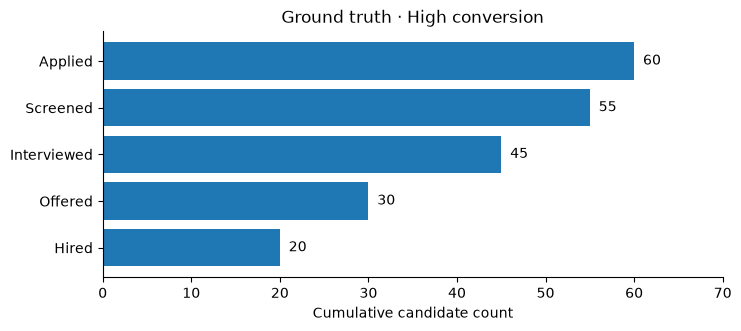

In [4]:
counts=[60,55,45,30,20]
stages=['Applied','Screened','Interviewed','Offered','Hired']
conversions=[100*counts[i+1]/counts[i] for i in range(4)]
ground_truth=pd.DataFrame({'Transition':[f'{stages[i]} → {stages[i+1]}' for i in range(4)],'From':counts[:-1],'To':counts[1:],'Conversion %':[round(x,2) for x in conversions],'Expected status':['OK']*4})
display(ground_truth.style.hide(axis='index').format({'Conversion %':'{:.2f}'}))
fig,ax=plt.subplots(figsize=(8,3.2));bars=ax.barh(stages[::-1],counts[::-1]);ax.set_xlim(0,70);ax.set_xlabel('Cumulative candidate count');ax.set_title('Ground truth · High conversion')
for bar,v in zip(bars,counts[::-1]):ax.text(v+1,bar.get_y()+bar.get_height()/2,str(v),va='center')
ax.spines[['top','right']].set_visible(False);plt.show()

## 04 / Automated report-risk indicators
These are **review prompts, not definitive hallucination classifiers**. The detector searches for strong language that may incorrectly treat non-conversions as confirmed offer declines; human review of full report and source metrics is still required.

In [5]:
import re
flags=[]
for _,r in df.iterrows():
    text=str(r.get('report') or '')
    patterns=[r'10 (?:candidates|offers?) (?:who )?(?:did not accept|declined|rejected)',r'10 unaccepted offers',r'10 candidates who received offers but were not hired']
    matches=[p for p in patterns if re.search(p,text,re.I)]
    flags.append({'Case':r['case'],'Prompt':r['version'],'Contains report':bool(text.strip()),'Potential offer-decline assumption':bool(matches), 'Manual check': 'Required' if matches else 'Optional'})
risk=pd.DataFrame(flags)
display(risk.style.hide(axis='index'))
if not risk['Contains report'].any():print('No full report text in loaded JSON; report-language audit unavailable.')

Case,Prompt,Contains report,Potential offer-decline assumption,Manual check
normal,baseline,True,False,Optional
normal,improved,True,False,Optional
screening_drop,baseline,True,False,Optional
screening_drop,improved,True,False,Optional
high_conversion,baseline,True,True,Required
high_conversion,improved,True,True,Required
zero_interviews,baseline,True,False,Optional
zero_interviews,improved,True,False,Optional
low_offers,baseline,True,False,Optional
low_offers,improved,True,False,Optional


## 05 / Evidence-based conclusion
The strongest supported claim is about **tool-use and workflow execution**, not about a statistically significant accuracy gain.

- **Observed:** matched-case PASS/FAIL outcomes and API failures above.
- **Observed in provided report text:** structured Prompt more explicitly separates observations, hypotheses, and rule limitations for `high_conversion`.
- **Still unresolved:** offer-to-hire non-conversion is not synonymous with an offer decline.
- **Limitations:** small synthetic test set, model stochasticity, shared Gemini quota, rubric focuses on tool calls rather than complete factual verification.

**Next controlled experiment:** add one rule to the improved Prompt: *"Describe offer-to-hire non-conversions as unresolved outcomes, not confirmed offer declines, unless reason codes prove a decline."* Save both reports, annotate claim accuracy for the same cases, and measure the change. Preserve all raw evidence rather than fabricating manual ratings.

In [6]:
out=DATA / 'evaluation_summary.csv'; DATA.mkdir(parents=True,exist_ok=True)
summary.to_csv(out,index=False)
print('Exported summary:',out)
print('Note: this is an evaluation summary, not a replacement for raw reports.')

Exported summary: /Users/vicmon/ZEIL/eval_results/evaluation_summary.csv
Note: this is an evaluation summary, not a replacement for raw reports.
